# Desafío Data Scientist Lead: Optimización Logística
**Notebook resumen.** Responde las preguntas específicas del desafío (Tareas 1 a 5) con los cálculos estrictamente necesarios y deja el detalle en los notebooks auxiliares. Toda la lógica vive en `src/logforecast`; aquí solo se llama y se muestra.

| Sección | Pregunta del desafío | Detalle adicional en |
|---|---|---|
| Tarea 1 | Centros que sub/sobreestiman; degradación D+1 a D+4 | `01_tarea1_wape_bias` (EDA, calidad de datos, bias móvil, consistencia fila a fila) |
| Tarea 2 | Bias del plan; % fuera de plan; métricas adicionales; estrategia del martes | `02_tarea2_plan_entrega` (gráficos por cliente, CD y canal; concentración de desvíos) |
| Tarea 3 | Modelo de corrección y backtest de origen rodante | `03_exploracion_t3` (baselines y rezagos), `04_validacion_cruzada_t3` (CV de ridge, ElasticNet y LightGBM) |
| Tarea 4 | Gate de 45 días y ventajas/riesgos del umbral | `05_tarea4_gate_t4` (cold start simulado, curva de aprendizaje, error por tramo de historia) |
| Tarea 5 | Arquitectura AWS | `06_tarea5_arquitectura_aws` (diagramas, componentes, contrato del endpoint, monitoreo) |
| Impacto en negocio | Faltante/sobrante, capacidad, KPIs | `07_diagnostico_capacidad` (pronóstico vs capacidad, efecto del recorte) |

**Convenciones.** WAPE = Σ|real − pronóstico| / Σ|real|. Bias = Σ(real − pronóstico) / Σ|real|: positivo = el pronóstico **subestima**, negativo = **sobreestima**. Los datos son 60 días (2026-01-01 a 2026-03-01) de 6 CD; todas las conclusiones valen para esa muestra.

In [1]:
import pandas as pd

from logforecast import capacity as C
from logforecast import cv, diagnostics, gate_study as gs, io, metrics, plan_analysis
from logforecast import evaluation as ev
from logforecast import features as F
from logforecast.config import Settings

S = Settings.from_env()
orders, fc, cap, plan = io.load_orders(S), io.load_forecasts(S), io.load_capacity(S), io.load_plan(S)
frame = diagnostics.build_eval_frame(orders, fc)  # una fila por (CD, emisión, despacho) con el real
CDS = sorted(frame[F.CD].unique())
print(f"pedidos {len(orders)} | pronósticos {len(fc)} | capacidad {len(cap)} | plan {len(plan)}")

pedidos 1080 | pronósticos 1380 | capacidad 360 | plan 739


## Tarea 1: Diagnóstico de calidad y backtesting
WAPE y bias por centro y por horizonte.

In [2]:
display(diagnostics.classify_bias(diagnostics.error_by_cd(frame), S.bias_tolerance).round(3))
display(diagnostics.error_by_horizon(frame).round(3))
por_cd_h = diagnostics.error_by_cd_horizon(frame)
display(por_cd_h.pivot(index=F.CD, columns=F.HOR, values="wape").round(3))
print("Control: WAPE por horizonte con todas las fechas vs solo fechas comunes a D+1..D+4")
diagnostics.horizon_wape_common_dates(frame).round(3)

,centro_distribucion,wape,bias,n,tendencia
0,CD_CENTRO,0.233,-0.202,230.0,sobreestima
1,CD_ESTE,0.259,0.253,230.0,subestima
2,CD_NORTE,0.098,0.075,230.0,subestima
3,CD_OESTE,0.239,-0.227,230.0,sobreestima
4,CD_PACIFICO,0.222,-0.216,230.0,sobreestima
5,CD_SUR,0.316,0.316,230.0,subestima


,horizonte,wape,bias,n
0,D+1,0.198,0.069,354.0
1,D+2,0.203,0.076,348.0
2,D+3,0.208,0.064,342.0
3,D+4,0.225,0.052,336.0


horizonte,D+1,D+2,D+3,D+4
centro_distribucion,,,,
CD_CENTRO,0.196,0.195,0.267,0.277
CD_ESTE,0.248,0.247,0.254,0.287
CD_NORTE,0.088,0.101,0.085,0.119
CD_OESTE,0.256,0.241,0.219,0.240
CD_PACIFICO,0.203,0.211,0.216,0.258
CD_SUR,0.317,0.323,0.319,0.303


Control: WAPE por horizonte con todas las fechas vs solo fechas comunes a D+1..D+4


,horizonte,wape_todas,n_todas,wape_comunes,n_comunes,dif_pp
0,D+1,0.198,354.0,0.196,336.0,-0.156
1,D+2,0.203,348.0,0.203,336.0,-0.021
2,D+3,0.208,342.0,0.207,336.0,-0.101
3,D+4,0.225,336.0,0.225,336.0,0.000


### 1.1 ¿Qué centros subestiman de manera consistente y cuáles sobreestiman?
Los 6 centros tienen un sesgo sistemático, 3 hacia cada lado:
- **Subestiman (bias > 0):** CD_SUR (+31,6 %), CD_ESTE (+25,3 %) y CD_NORTE (+7,5 %).
- **Sobreestiman (bias < 0):** CD_OESTE (−22,7 %), CD_PACIFICO (−21,6 %) y CD_CENTRO (−20,2 %).

El signo se mantiene en los 4 horizontes y en el tiempo (el bias móvil de 7 días no cruza el cero en ningún CD). En 5 de los 6 CD el WAPE es casi igual al valor absoluto del bias, es decir, el error es casi todo **sistemático y por tanto corregible**. CD_NORTE es el mejor (WAPE 9,8 %). El bias global (+6,5 %) enmascara sesgos opuestos de ±20 a 30 % entre CD, por lo que evaluar y corregir debe hacerse **por CD**.

*Más detalle (bias móvil, consistencia fila a fila, calidad de datos, real por canal):* `01_tarea1_wape_bias`.

### 1.2 ¿Cómo se degrada el WAPE de D+1 a D+4?
La degradación global es moderada y no lineal: **D+1 19,8 % → D+2 20,3 % → D+3 20,8 % → D+4 22,5 %** (+2,8 puntos, ~14 % relativo). Hasta D+3 sube ~0,5 puntos por día; el salto mayor está entre D+3 y D+4 (+1,7 puntos). Restringiendo a las fechas comunes a los 4 horizontes el WAPE cambia menos de 0,2 puntos (tabla de control), así que la tendencia no se debe a que cada horizonte evalúe fechas distintas.

Por CD el patrón es heterogéneo:
- **Se degradan claramente:** CD_CENTRO (19,6 % → 27,7 %, con salto en D+3), CD_PACIFICO (20,3 % → 25,8 %, gradual) y CD_ESTE (24,8 % → 28,7 %, con salto en D+4).
- **Se degrada poco y no de forma monótona:** CD_NORTE (8,8 % → 11,9 %; D+3 es menor que D+2).
- **No se degradan:** CD_SUR (31,7 % → 30,3 %) y CD_OESTE (25,6 % → 24,0 %); su error es sobre todo sesgo constante, que no depende de la anticipación.

El horizonte pesa mucho menos que el CD: ~3 puntos entre D+1 y D+4 frente a un rango de 9,8 % a 31,6 % entre CD. Por eso la corrección del sesgo por CD es la palanca principal de la Tarea 3.

## Tarea 2: Estado del plan de entrega
*El plan cubre 90 clientes (~15 % del volumen total) y solo tiene días hábiles; las conclusiones valen para esa muestra.*

In [3]:
print(plan_analysis.plan_bias(plan))
display(pd.Series(plan_analysis.plan_bias_detail(plan)))
display(pd.concat({by: plan_analysis.plan_bias_by(plan, by).set_index(by)["bias_unidades"]
                   for by in ["centro_distribucion", "canal_venta", "fuera_de_plan"]}).round(3).to_frame())
display(pd.Series(plan_analysis.out_of_plan_date_shift(plan)).round(3))
display(plan_analysis.out_of_plan_rate(plan))
display(plan_analysis.out_of_plan_rate(plan, "centro_distribucion"))
display(plan_analysis.out_of_plan_rate(plan_analysis.enrich_plan(plan), "dow_plan"))
print("Test chi² (H0: la tasa fuera de plan es igual en todos los grupos):")
pd.DataFrame({by: plan_analysis.out_of_plan_chi2(plan, by) for by in ["centro_distribucion", "dow_plan"]}).T

{'bias_unidades': 0.10617604720714775, 'wape_unidades': 0.15629005901653636, 'desvio_fecha_medio_dias': 0.4438430311231394, 'desvio_fecha_mediano_dias': 0.0}


pct_compras_real_sobre_plan     0.711773
clientes_real_sobre_plan       81.000000
clientes                       90.000000
dtype: float64

bias_unidades
centro_distribucion CD_ESTE                      0.141
                    CD_PACIFICO                  0.128
                    CD_NORTE                     0.110
                    CD_SUR                       0.103
                    CD_OESTE                     0.092
                    CD_CENTRO                    0.082
canal_venta         ATENCION_TELEFONICA          0.108
                    PORTAL_WEB                   0.108
                    AGENTE_COMERCIAL             0.099
fuera_de_plan       1                            0.169
                    0                            0.089

n_fuera_de_plan               129.000
pct_despues                     0.775
pct_antes                       0.225
desvio_medio_neto_dias          2.543
atraso_medio_dias               3.840
atraso_max_dias                 7.000
adelanto_min_dias              -1.000
adelanto_max_dias              -3.000
pct_aterriza_martes             0.597
pct_aterriza_fin_de_semana      0.171
dtype: float64

,fuera_de_plan,n
0,0.17456,739


,centro_distribucion,fuera_de_plan,n
2,CD_NORTE,0.243902,123
4,CD_PACIFICO,0.213115,122
1,CD_ESTE,0.194915,118
5,CD_SUR,0.188525,122
0,CD_CENTRO,0.111111,126
3,CD_OESTE,0.101562,128


,dow_plan,fuera_de_plan,n
3,Mie,0.229358,109
1,Lun,0.221154,104
2,Mar,0.162162,259
4,Vie,0.155172,116
0,Jue,0.139073,151


Test chi² (H0: la tasa fuera de plan es igual en todos los grupos):


,chi2,gl,p_valor,n
centro_distribucion,14.121648,5.0,0.014855,739.0
dow_plan,5.737148,4.0,0.219657,739.0


### 2.1 ¿Existe un bias en el plan (unidades y fechas)?
**Sí en unidades: el plan subestima sistemáticamente lo que los clientes compran.** Bias de **+10,6 %** (WAPE 15,6 %); en el 71 % de las compras el real supera al plan y 81 de los 90 clientes compran más de lo planificado. Es consistente entre CD (+8,2 % CENTRO a +14,1 % ESTE) y entre canales (+9,9 % a +10,8 %), por lo que parece un sesgo del proceso de planificación y no de un CD o canal. Las compras que cumplen la fecha también superan el plan (+8,9 %); las fuera de plan lo superan más (+16,9 %).

**En fechas el sesgo es pequeño y se concentra en los desvíos:** mediana 0 días y media +0,44 días. Entre las compras fuera de plan, el 77,5 % ocurre **después** de lo planificado (atraso medio +3,8 días, hasta +7) y el 22,5 % antes (−1 a −3 días); considerando ambos sentidos, el desvío medio neto es +2,5 días.

### 2.2 Compras fuera de plan
- **Total: 17,5 %** (129 de 739 compras).
- **Por CD** (diferencia significativa, chi² p = 0,015): NORTE 24,4 %, PACIFICO 21,3 %, ESTE 19,5 %, SUR 18,9 %, CENTRO 11,1 %, OESTE 10,2 %.
- **Por día de la semana planificado:** miércoles 22,9 %, lunes 22,1 %, martes 16,2 %, viernes 15,5 %, jueves 13,9 %. **No es estadísticamente significativa** (chi² p = 0,22), por lo que no conviene atribuirla a un día concreto.
- **Adónde van:** el 59,7 % de las compras fuera de plan termina cayendo en martes y el 17 % cae en fin de semana, que el plan no contempla.

### 2.3 Métricas adicionales
Adhesión por cliente, concentración de desvíos y peso de cada día de la semana (el resto de las métricas propuestas se justifica en la tabla).

In [4]:
display(pd.Series(plan_analysis.adherence_summary(plan)))
print(f"top 20 % de clientes por desvío en unidades: {plan_analysis.deviation_concentration(plan):.1%} del desvío absoluto | "
      f"top 20 % por n° de compras fuera de plan: {plan_analysis.out_of_plan_concentration(plan):.1%} de esas compras")
print("Peso de cada día de la semana (% de unidades):")
(plan_analysis.weekday_share(plan, orders) * 100).round(1)

clientes_nunca_fuera    31.000000
clientes_fuera_>=30%    20.000000
max_pct_fuera_plan       0.666667
dtype: float64

top 20 % de clientes por desvío en unidades: 47.5% del desvío absoluto | top 20 % por n° de compras fuera de plan: 52.7% de esas compras
Peso de cada día de la semana (% de unidades):


,pct_unidades_plan,pct_unidades_reales_plan,pct_pedidos_totales,uniforme
dia,,,,
Lun,13.3,9.7,13.0,14.3
Mar,33.0,46.2,16.6,14.3
Mie,19.5,13.8,13.3,14.3
Jue,15.4,12.8,14.8,14.3
Vie,18.8,14.1,15.1,14.3
Sab,0.0,0.9,14.7,14.3
Dom,0.0,2.6,12.5,14.3


| Métrica | Por qué aporta |
|---|---|
| **Adhesión por cliente** (% de compras en la fecha planificada) | Separa a los clientes confiables de los que no. 31 de 90 nunca se salen del plan y 20 se salen en ≥30 % de sus compras (máximo 67 %). |
| **Variación de fecha con signo** (días real − plan) | Distingue adelantar de atrasar, que tienen costos logísticos distintos. |
| **Variación de volumen por compra** (% real vs plan) | Mide cuánto se desvía cada compra, no solo el total. |
| **Concentración de desvíos** | Ordenando por desvío absoluto en unidades, el 20 % de los clientes explica el 47,5 % del desvío; ordenando por número de compras fuera de plan, el 20 % concentra el 52,7 % de esas compras. Son grupos distintos, pero en ambos casos basta intervenir en pocos clientes. |
| **Día de aterrizaje de las compras fuera de plan** | Muestra hacia qué días se desplaza la demanda (el martes concentra el ~60 %). |
| **Utilización de capacidad por CD y día** | Conecta los desvíos con el riesgo operativo (días sobre el 90 % de la capacidad; ver `07_diagnostico_capacidad`). |

### 2.4 Estrategia para aplanar la curva del martes
**Diagnóstico.** El martes concentra el 33 % de las unidades planificadas y el 46 % de las compras reales de la muestra; los clientes que se salen del plan tienden a ir hacia el martes. En el total de pedidos el pico es más suave (16,6 % vs ~14,3 % si fuera uniforme), así que el 46 % no debe extrapolarse al negocio completo.

**Mecanismo: recomendación de fecha con capacidad y con incentivo.** La plataforma ya recomienda fechas dinámicas. Se propone:
1. Segmentar a los clientes por flexibilidad (adhesión y variación de fecha); los flexibles son el objetivo principal.
2. Estimar la utilización esperada por CD y día como pronóstico corregido ÷ capacidad (el endpoint ya la entrega: `capacidad_maxima`, `uso_capacidad`, `alerta_capacidad`).
3. Cuando un día supere un umbral (p. ej. 85 a 90 %), ofrecer fechas alternativas cercanas con un incentivo (descuento, flete sin costo o prioridad de despacho) y mostrar la capacidad restante.
4. Cupos blandos al martes para los clientes flexibles, sin forzar a los de baja flexibilidad.

**Implementación.** Piloto en CD_NORTE (mayor tasa fuera de plan, 24,4 %, y el CD con más días sobre la capacidad: 6 de los 13 CD-día en que el real superó el tope; la coincidencia no demuestra causalidad), contra un CD de control durante 4 a 8 semanas.

**KPI principal:** razón pico/promedio diaria por CD (máximo ÷ media de unidades por día). Complementarios: coeficiente de variación de la demanda diaria; % de días sobre el 90 % de capacidad y número de fletes de emergencia; % de la demanda que cae en martes; tasa de aceptación de la fecha alternativa y adhesión al plan (para controlar que el incentivo no deteriore el servicio).

*Más detalle (gráficos por cliente, CD y canal):* `02_tarea2_plan_entrega`.

## Tarea 3: Modelo complementario de forecast
### Metodología
- **Objetivo:** `y = log1p(real) − log1p(pronóstico)`, un error relativo en escala log. El modelo predice ese error y el pronóstico corregido es `expm1(log1p(pron) + delta)`, acotado a ≥ 0.
- **Features** (todas causales: solo usan lo conocido al emitir; el real se conoce con 1 día de rezago): día de la semana del despacho (ordinal, 0 = lunes) y fin de semana, horizonte, errores móviles de 7 y 14 días (`err_7`, `err_14`), pronóstico vs promedio reciente del real (`pron_vs_rec7`), real del mismo día de la semana anterior (`lag7_rel`), indicador de pico (cuantil 80 % solo del pasado) y su margen, y dummies de CD.
- **Validación de origen rodante con ventana expansiva:** en cada origen t se entrena con lo conocido hasta t − 1 y se evalúa lo emitido en t. **Train** = orígenes 22-ene a 13-feb (toda la selección de modelo se hace aquí, con 4 bloques contiguos para medir dispersión). **Test** = orígenes 14-feb a 28-feb, con el modelo congelado al inicio de test y sin reajustes.
- **Modelos:** ridge (5 valores de `alpha`), ElasticNet (16 combinaciones) y LightGBM (8), más los baselines simples.
- **Regla de decisión (solo con train):** un candidato reemplaza a la referencia `ratio_mov14` (factor por CD con los últimos 14 días; el mejor baseline en train, ver `03_exploracion_t3`) si su WAPE de CV es menor y gana en al menos 3 de 4 bloques. Para ElasticNet y LightGBM se compara además contra el mejor ridge.

In [5]:
AVAIL_LAG = 1
BASELINES = {"base": ev.SPEC_BASE, "seasonal_naive": dict(kind="snaive"), "ratio_cd": ev.SPEC_RATIO_CD,
             "ratio_cd_h": dict(kind="ratio", by=[F.CD, F.HOR]), "ratio_mov14": ev.SPEC_RATIO_MOV14}
_, _, tabs_base = ev.run_models(frame, BASELINES, AVAIL_LAG)
print("Baselines, WAPE global (%):")
display((pd.DataFrame({z: t.loc["GLOBAL"] for z, t in tabs_base.items()}).T * 100).round(1))

feat = F.build_features(frame, avail_lag=AVAIL_LAG)
study = cv.run_cv_study(feat, {**cv.ridge_specs(), **cv.enet_specs(), **cv.lgbm_specs()}, AVAIL_LAG)
print(study.info())
print("Mejor configuración de cada familia en CV (train):")
display(study.best_table())
display(study.decision())
ganador = study.winner()
print("DECISIÓN:", f"usar {ganador}" if ganador else f"quedarse con {study.ref_name}")
assert ganador and study.best[ganador] == cv.ELEGIDO, "actualizar cv.ELEGIDO"

Baselines, WAPE global (%):


,base,seasonal_naive,ratio_cd,ratio_cd_h,ratio_mov14
train,20.8,12.0,9.5,9.5,9.5
test,20.3,13.7,9.1,9.0,9.2


CV (train): 23 origenes | entrena con 444 filas (primero) a 972 (ultimo) | filas de CV: 516
Test: 15 origenes | modelo unico entrenado con 996 filas
base: 20.76% | ratio_mov14: 9.46%
Mejor configuración de cada familia en CV (train):


,mejor config,WAPE CV (%)
ridge,alpha=100,7.78
enet,l1_ratio=0.1 alpha=0.1,7.73
lgbm,leaves=8 n=100 min_child=20,7.84


,config,WAPE CV (%),ratio_mov14 (%),bloques vs ratio_mov14,reemplaza a ratio_mov14,bloques vs ridge,mejor que ridge
ridge,alpha=100,7.78,9.46,4/4,True,NaN,NaN
enet,l1_ratio=0.1 alpha=0.1,7.73,9.46,4/4,True,2/4,False
lgbm,leaves=8 n=100 min_child=20,7.84,9.46,4/4,True,3/4,False


DECISIÓN: usar enet


In [6]:
ho, tab_ho, dif_ho = study.holdout()
print(f"Test (orígenes 14-feb a 28-feb, {len(ho['base'])} filas). WAPE (%) por CD:")
display((tab_ho * 100).round(1))
print("Diferencia en puntos de WAPE (negativo = el modelo mejora):")
dif_ho.loc[["GLOBAL"]].round(2)

Test (orígenes 14-feb a 28-feb, 324 filas). WAPE (%) por CD:


,base,ratio_cd,ratio_mov14,ridge_cv,enet_cv,lgbm_cv
GLOBAL,20.3,9.1,9.2,7.3,7.3,7.6
CD_CENTRO,21.9,12.5,12.7,8.2,8.3,7.2
CD_ESTE,25.6,16.1,16.2,10.6,10.7,10.1
CD_NORTE,9.1,7.4,7.6,7.3,7.1,7.8
CD_OESTE,23.5,8.4,9.2,6.7,7.3,6.3
CD_PACIFICO,24.5,8.3,8.0,6.4,7.0,6.0
CD_SUR,31.4,6.8,6.7,6.1,5.5,7.5


Diferencia en puntos de WAPE (negativo = el modelo mejora):


,ridge_cv - ratio_mov14,enet_cv - ratio_mov14,lgbm_cv - ratio_mov14,enet_cv - ridge_cv,lgbm_cv - ridge_cv
GLOBAL,-1.82,-1.91,-1.55,-0.09,0.28


### Resultados y lectura (WAPE global)
| | Base | `ratio_mov14` (referencia) | Ridge | ElasticNet (elegido) | LightGBM |
|---|---|---|---|---|---|
| **CV, train** | 20,8 % | 9,46 % | 7,78 % | 7,73 % | 7,84 % |
| **Test (congelado)** | 20,3 % | 9,2 % | 7,3 % | 7,3 % | 7,6 % |

- **Modelo elegido: ElasticNet** (`l1_ratio=0,1`, `alpha=0,1`): menor WAPE de CV y reemplaza a la referencia en los 4 bloques.
- **Supera ampliamente al base:** de 20,3 % a 7,3 % de WAPE en test (−13 puntos, −64 %), y en los 6 CD: CENTRO 21,9 % → 8,3 %, ESTE 25,6 % → 10,7 %, NORTE 9,1 % → 7,1 %, OESTE 23,5 % → 7,3 %, PACIFICO 24,5 % → 7,0 % y SUR 31,4 % → 5,5 %.
- **Gran parte de la mejora viene de corregir el sesgo por CD:** `ratio_mov14` por sí solo baja el WAPE a 9,2 % (−11,1 puntos). El modelo agrega −1,9 puntos usando la relación del pronóstico con la demanda reciente (`pron_vs_rec7`, `lag7_rel`); `err_7` y `err_14` pesan casi 0 porque las dummies de CD ya capturan el sesgo.
- **Los tres modelos empatan en la práctica:** en CV quedan a 0,11 puntos (ElasticNet le gana al ridge en solo 2 de 4 bloques) y en test ElasticNet y ridge quedan en 7,3 %. Se elige ElasticNet porque lo indica la regla, definida antes de mirar test; el ridge sería igual de defendible.
- **LightGBM no justifica su complejidad:** 7,6 % en test; mejor en CENTRO, ESTE, OESTE y PACIFICO, pero en NORTE y SUR queda peor incluso que `ratio_mov14`. Con ~2 meses de datos los árboles tienen pocas filas.
- **Dónde queda error:** CD_ESTE (10,7 %) tiene una dinámica semanal que ni los factores por CD ni las features capturan del todo (es el único CD donde el `seasonal_naive` le gana a los ratios).
- **Producción:** el pipeline usa este mismo ElasticNet (`ElasticNetCorrector`) detrás del gate; un test verifica que predice igual que el backtest.
- **Honestidad analítica:** el mejor ElasticNet usa el `alpha` más alto de la grilla y el mejor LightGBM queda en el borde en sus tres hiperparámetros (ampliar las grillas queda pendiente); la selección usa los mismos orígenes que las grillas; orígenes consecutivos no son independientes; test son 15 orígenes (~324 filas), por lo que diferencias de décimas no son concluyentes; `dia_semana` es ordinal y en los modelos lineales no representa un pico en martes; no hay estacionalidad anual ni feriados en la muestra.

*Más detalle:* baselines y 4 rezagos en `03_exploracion_t3`; CV de los tres modelos (grillas, dispersión por bloques, coeficientes e importancias) en `04_validacion_cruzada_t3`.

## Tarea 4: Regla de resiliencia (cold start / gate de historia mínima)
El gate vive en `logforecast.gate` (`evaluate_gate`) y se usa en `GatedCorrector`, que envuelve al `ElasticNetCorrector` de la Tarea 3: **menos de 45 días de historia continua → fallback (pronóstico base, sin excepciones); 45 o más → se habilita el modelo**. Los días continuos se cuentan hasta la última fecha con datos y un hueco reinicia la cuenta; al emitir en `t` solo se conoce el real hasta `t − 1`.

In [7]:
MIN_DAYS = 45
hist = gs.history_frame(orders)
estado = pd.concat({f: gs.gate_state(hist, f, CDS, MIN_DAYS) for f in ["2026-02-13", "2026-02-14"]}, names=["as_of", "CD"])
print("Días de historia continua y estado del gate (as_of = último real conocido):")
display(estado.unstack("as_of"))
primero = gs.first_open_date(hist, CDS, MIN_DAYS, AVAIL_LAG, "2026-01-02", "2026-03-01")
print(f"Primer día de emisión con el gate abierto en los 6 CD: {primero:%Y-%m-%d}")
print("Casos borde (el gate nunca lanza excepciones):")
display(gs.edge_cases(hist, CDS, "2026-02-28", MIN_DAYS))
print(f"Cold start simulado: {CDS[-1]} empieza a operar el 1-feb; GatedCorrector con el ElasticNet de producción, emisión del 28-feb:")
dec, chequeo = gs.cold_start_demo(frame, CDS, CDS[-1], "2026-02-01", "2026-02-28", MIN_DAYS, AVAIL_LAG)
dec[["status", "continuous_days", "reason"]].join(chequeo[["pred == base"]])

Días de historia continua y estado del gate (as_of = último real conocido):


dias                estado           
as_of       2026-02-13 2026-02-14 2026-02-13 2026-02-14
CD                                                     
CD_CENTRO           44         45   FALLBACK      TRAIN
CD_ESTE             44         45   FALLBACK      TRAIN
CD_NORTE            44         45   FALLBACK      TRAIN
CD_OESTE            44         45   FALLBACK      TRAIN
CD_PACIFICO         44         45   FALLBACK      TRAIN
CD_SUR              44         45   FALLBACK      TRAIN

gate fallo globalmente: 'fecha_despacho'


Primer día de emisión con el gate abierto en los 6 CD: 2026-02-15
Casos borde (el gate nunca lanza excepciones):


,excepción,decisiones,en TRAIN,en FALLBACK
historia vacía,no,6,0,"CD_CENTRO (0d), CD_ESTE (0d), CD_NORTE (0d), C..."
CD sin datos (CD_CENTRO),no,6,5,CD_CENTRO (0d)
hueco el 10-feb en CD_ESTE,no,6,5,CD_ESTE (18d)
filas duplicadas,no,6,6,-
columna de fecha faltante,no,0,0,todos (sin decisión)


Cold start simulado: CD_SUR empieza a operar el 1-feb; GatedCorrector con el ElasticNet de producción, emisión del 28-feb:


,status,continuous_days,reason,pred == base
CD_CENTRO,TRAIN,57,historia suficiente,False
CD_ESTE,TRAIN,57,historia suficiente,False
CD_NORTE,TRAIN,57,historia suficiente,False
CD_OESTE,TRAIN,57,historia suficiente,False
CD_PACIFICO,TRAIN,57,historia suficiente,False
CD_SUR,FALLBACK,27,historia insuficiente (27 < 45 dias),True


### Ventajas y riesgos de mover el umbral, con números
Primero la curva de aprendizaje (WAPE según los días de historia con que se entrena, sobre las mismas filas). Después, para cada umbral `T`, se aplica el gate real en cada origen (15-ene a 28-feb): los CD con al menos `T` días usan el modelo y el resto el base. El IC 90 % es un remuestreo de orígenes (guía, no intervalo exacto: los orígenes son dependientes). Modelos: el ElasticNet elegido y la referencia `ratio_mov14`, con configuración fija.

In [8]:
MODELOS = gs.default_models()  # referencia ratio_mov14 y ElasticNet elegido, configuración fija
FAM = cv.ELEGIDO[0]
curva, n_filas = gs.learning_curve(feat, pd.date_range("2026-02-15", "2026-02-28"), [14, 21, 28, 35, 45, None],
                                   AVAIL_LAG, MODELOS)
print(f"Curva de aprendizaje: WAPE (%) según días de historia usados para entrenar ({n_filas} filas, orígenes 15 al 28-feb):")
display((curva * 100).round(2))

ORIG_ALL = pd.date_range("2026-01-15", "2026-02-28")
D, tramos = gs.backtest_by_history(feat, hist, CDS, ORIG_ALL, AVAIL_LAG, MODELOS)
print("WAPE (%) según los días de historia continua al emitir:")
display(tramos.round(2))

abierto = gs.open_status(hist, CDS, ORIG_ALL, [14, 21, 28, 35, 45, 52], AVAIL_LAG)
print(f"Sistema con gate ({FAM}). Base sin gate: {gs.wape(D, 'pred_base') * 100:.1f} % | "
      f"{FAM} sin gate: {gs.wape(D, f'pred_{FAM}') * 100:.1f} %")
gs.simulate_thresholds(D, abierto, FAM).round(2)

Curva de aprendizaje: WAPE (%) según días de historia usados para entrenar (300 filas, orígenes 15 al 28-feb):


,base,ratio_mov14,enet
días de historia (ventana),,,
14,20.43,8.91,7.59
21,20.43,8.91,7.36
28,20.43,8.91,7.39
35,20.43,8.91,7.31
45,20.43,8.91,7.44
todo,20.43,8.91,7.28


WAPE (%) según los días de historia continua al emitir:


,orígenes,filas,base,ratio_mov14,enet,ratio_mov14 - base (pp),enet - base (pp)
días de historia,,,,,,,
14-20,7.0,168.0,21.80,9.87,8.13,-11.93,-13.67
21-27,7.0,168.0,20.58,9.92,7.78,-10.66,-12.80
28-34,7.0,168.0,20.73,9.46,8.62,-11.27,-12.11
35-44,10.0,240.0,21.11,9.71,7.46,-11.40,-13.65
45+,14.0,300.0,20.43,8.91,7.28,-11.52,-13.15


Sistema con gate (enet). Base sin gate: 20.9 % | enet sin gate: 7.8 %


,cobertura (%),WAPE gate (%),vs base (pp),vs modelo sin gate (pp),IC90 vs base (pp)
umbral T (días),,,,,
14,100.0,7.753567,-13.127354,0.0,"[-13.65, -12.65]"
21,83.908046,9.948968,-10.931953,2.195402,"[-12.16, -9.64]"
28,67.816092,11.967143,-8.913778,4.213576,"[-10.47, -7.44]"
35,51.724138,13.924665,-6.956256,6.171098,"[-8.47, -5.26]"
45,28.735632,17.11731,-3.763611,9.363744,"[-5.18, -2.31]"
52,12.643678,19.143761,-1.73716,11.390195,"[-2.83, -0.64]"


**Lo que muestran los datos**
- **El gate funciona y no lanza excepciones:** se abre el 15-feb para los 6 CD a la vez (45 días de historia continua; el 13-feb tienen 44), los casos borde caen al fallback sin errores y, en el cold start simulado, el CD que empezó el 1-feb (27 días) queda en fallback con el pronóstico base intacto mientras los demás se corrigen. Con un inicio común no se puede observar el cold start de un CD real; por eso se simula.
- **El modelo no necesita 45 días para ganarle al base:** entrenado con solo 14 días tiene WAPE 7,59 % contra 20,43 % del base; desde 21 días queda a décimas de lo que logra con toda la historia (7,28 %) y la curva no es monótona (45 días: 7,44 %).
- **Tampoco empeora con poca historia:** por tramo de historia al emitir, el ElasticNet le gana al base en todos los tramos por al menos 12 puntos, incluido el de 14 a 20 días (8,13 % contra 21,80 %).
- **Subir el umbral solo quita cobertura:** con T = 14 la cobertura es 100 % y el WAPE del sistema 7,75 %; con T = 21, 83,9 % y 9,95 %; con T = 45, 28,7 % y 17,12 % (deja 9,4 puntos de mejora sin usar en este período); con T = 52, 12,6 % y 19,14 %. El IC 90 % de la diferencia con el base queda bajo cero para todos los umbrales: abrir antes nunca empeoró al base.
- **Riesgos de bajar el umbral:** coeficientes más inestables con pocas filas, que esta muestra no permite medir bien (todos los CD parten el mismo día, ~2 meses, sin estacionalidad); y un mínimo técnico: `pico_margen` necesita 14 días de reales y `lag7_rel` 7, así que con menos de ~15 días esas features quedan imputadas en 0.

**Recomendación.** Implementar 45 días porque es el requisito y una posición conservadora, configurable con `LF_MIN_HISTORY_DAYS`. Los datos respaldan bajarlo a **21 días** (3 semanas completas: cubre `lag7_rel` y el día de la semana, y desde ahí la curva ya se estabilizó), pero hay que validarlo con CD que realmente entren en operación en momentos distintos y con más historia antes de cambiarlo en producción.

*Más detalle (curva de aprendizaje y gráficos, tramos, simulación por umbral):* `05_tarea4_gate_t4`.

## Tarea 5: Arquitectura e infraestructura cloud (AWS)
Diseño conceptual (no desplegado). Cada pieza se eligió para que el mismo código (`logforecast`) corra en batch, en inferencia y en el notebook, cambiando solo variables de entorno.


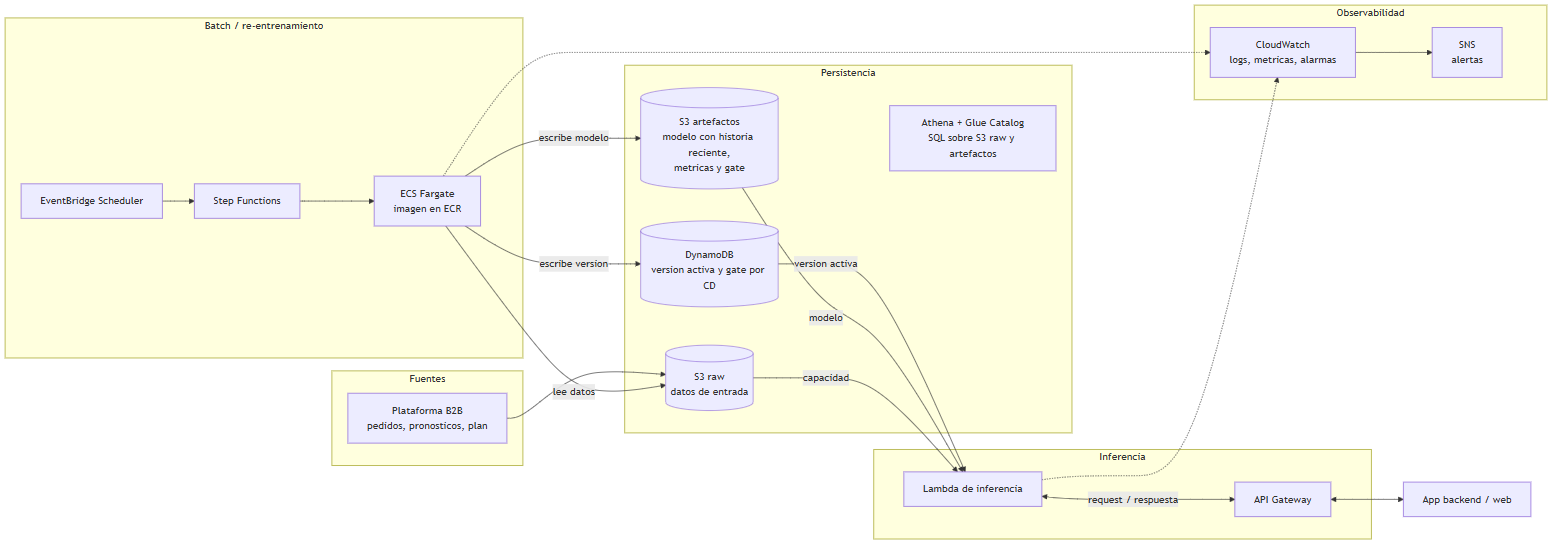

In [9]:
from IPython.display import Image

Image(filename="../docs/diagramas/01_arquitectura.png", width=1000)

| Componente | Servicio | Rol |
|---|---|---|
| **Batch / re-entrenamiento** | EventBridge → Step Functions → ECS Fargate (imagen en ECR) | Cada día: valida calidad de datos, evalúa el gate por CD, reentrena el ElasticNet y deja en el artefacto la historia reciente que necesitan las features. Solo publica el modelo nuevo si pasa el backtest. |
| **Inferencia / recomendación** | API Gateway → Lambda | Recibe registros (CD, emisión, despacho, horizonte, pronóstico base) y devuelve el corregido. Si el CD está en fallback o es desconocido, o el modelo falla, devuelve el base con `corregido: false` (200 con un número usable); un request sin las columnas obligatorias responde 400. |
| **Persistencia de datos** | S3 (raw y artefactos), Athena/Glue | Datos de entrada, modelos versionados (con la historia reciente para las features), métricas, decisiones del gate y consulta analítica. |
| **Persistencia de estado** | DynamoDB | Versión activa del modelo (revertir = mover un puntero) y estado del gate por CD. |
| **Monitoreo** | CloudWatch + SNS | WAPE y bias del corregido contra el base por CD en ventanas de 7 y 14 días; alarma y apagado de la corrección si el corregido es peor que el base varios días seguidos. |

**Contrato del endpoint (extracto).** Cada registro devuelve `unidades_corregidas`, `corregido` y la **capacidad del día con una alerta**: `capacidad_maxima`, `uso_capacidad` y `alerta_capacidad` (`OK`, `CERCA` desde 90 %, `EXCEDE` sobre 100 %, `SIN_CAPACIDAD`). La alerta no modifica las unidades: la app decide si recorta, reasigna o avisa.

**Implementado en el repo:** entrenamiento (`cli train`), inferencia (handler de Lambda) con gate, fallback y alerta de capacidad. **Solo diseño:** Step Functions, DynamoDB, publicación condicionada al backtest y monitoreo.

*Más detalle (diagramas de batch e inferencia, contrato completo, persistencia, monitoreo y rollback, alternativas):* `06_tarea5_arquitectura_aws`; diagramas en `docs/diagramas/`.

## Impacto en negocio
Sin datos de costos no se estiman montos; se usan proxies en unidades sobre el período de test.
- **Faltante** (real > pronóstico): demanda no cubierta por el plan; es el riesgo de contratar fletes de emergencia.
- **Sobrante** (pronóstico > real): capacidad de carga reservada de más.

In [10]:
MOD = f"{cv.ELEGIDO[0]}_cv"
res_impacto = {"base": ho["base"], ev.REF_NAME: ho[ev.REF_NAME], MOD: ho[MOD]}
display(ev.unit_gaps(res_impacto))
bias_cd = pd.DataFrame({k: r.groupby(F.CD).apply(lambda d: metrics.bias(d[F.REAL], d["pred"]), include_groups=False) * 100
                        for k, r in res_impacto.items()})
print("Bias por CD en test (%):")
display(bias_cd.round(1))

# alertas de capacidad que dispararía el endpoint sobre las predicciones de test
alertas = {k: C.capacity_alert(r, cap, pred_col="pred", warn_ratio=S.capacity_warn_ratio)["alerta_capacidad"].value_counts()
           for k, r in res_impacto.items()}
pd.DataFrame(alertas).fillna(0).astype(int)

,real total,faltante,sobrante,error absoluto,faltante (% del real),sobrante (% del real)
base,473653.0,63610.0,32612.5,96222.5,13.4,6.9
ratio_mov14,473653.0,19592.0,23845.9,43437.8,4.1,5.0
enet_cv,473653.0,15468.4,18930.0,34398.4,3.3,4.0


Bias por CD en test (%):


,base,ratio_mov14,enet_cv
centro_distribucion,,,
CD_CENTRO,-17.9,0.1,-1.5
CD_ESTE,24.7,-1.1,0.9
CD_NORTE,7.2,-2.1,-0.1
CD_OESTE,-22.4,-3.0,-3.5
CD_PACIFICO,-23.7,-0.9,-2.7
CD_SUR,31.4,0.7,-0.4


,base,ratio_mov14,enet_cv
alerta_capacidad,,,
CERCA,47,50,49
EXCEDE,76,38,8
OK,201,236,267


- **Menos faltante:** con el ElasticNet la demanda no cubierta cae de ~63.600 a ~15.500 unidades (−76 %), de 13,4 % a 3,3 % del real (con `ratio_mov14`, 4,1 %). Es la señal más directa de menor necesidad de fletes de emergencia.
- **Menos sobrante:** de ~32.600 a ~18.900 unidades (−42 %), de 6,9 % a 4,0 % del real: menos camiones y capacidad reservada sin uso.
- **Capacidad:** en test el base propone más de la capacidad diaria en 76 de 324 pronósticos (23,5 %; casi siempre sobreestimando, en CD_CENTRO, CD_OESTE y CD_PACIFICO); con el ElasticNet las alertas `EXCEDE` bajan a 8 (2,5 %). El real casi no satura (uso medio ~80 %; supera el tope en 13 de 360 CD-día), así que el recorte a la capacidad es una regla de seguridad de producción y no una mejora del modelo (detalle en `07_diagnostico_capacidad`).
- **Nivel de servicio:** el sesgo por CD en test baja de entre −23,7 % y +31,4 % (base) a un máximo de 3,5 % en valor absoluto (CD_OESTE). Esto mejora la cobertura del plan, pero no se puede traducir a fill rate sin datos de servicio.

### KPIs propuestos
| KPI | Qué mide |
|---|---|
| WAPE y bias del corregido vs base, por CD y horizonte | Calidad del modelo y detección de deriva (dispara el rollback). |
| Faltante y sobrante (unidades y % del real) | Proxy de flete de emergencia y de capacidad ociosa. |
| % de días ≥ 90 % de capacidad y alertas `EXCEDE` por CD | Riesgo operativo y utilidad de la alerta de capacidad. |
| Razón pico/promedio diaria y % de demanda en martes | Efecto de la estrategia de aplanamiento. |
| Tasa de compras fuera de plan y adhesión al plan | Calidad del plan y de la recomendación de fecha. |
| Cobertura del gate (% de CD con modelo activo) | Salud del mecanismo de resiliencia. |
| Número y costo de fletes de emergencia; fill rate / OTIF | Impacto económico y de servicio (requieren datos que no están en el paquete). |

## Alcance y límites
- **Fuera de alcance:** costos y datos de servicio; estacionalidad anual y feriados; arquitectura no desplegada (solo diseño; publicación condicionada, DynamoDB y monitoreo no implementados); validación del umbral con CD que entren en momentos distintos; ampliar las grillas de ElasticNet y LightGBM.
- **Reproducibilidad:** `docker compose up --build` y ejecutar los notebooks en orden; `docker compose run --rm tests` corre los tests.